Phase 1 — imports:

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_auc_score, f1_score, precision_score, recall_score,
)

RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

print("Libraries loaded ✅")

Libraries loaded ✅


Phase 2 — Load the Week 5 artifacts

## 1. Load Preprocessed Data
The four CSVs are the direct output of the Week 5 pipeline: 30 features, one-hot
encoded, with `tenure` / `MonthlyCharges` / `TotalCharges` standardised using
statistics fitted on the training split only.

Row alignment between `X_train` and `y_train` is preserved because both were written
from the same split with `index=False`.

In [58]:
BASE = "https://raw.githubusercontent.com/NarenMSD/getintern-week5-telco-churn-ml-preprocessor/main/"

X_train = pd.read_csv(BASE + "X_train.csv")
X_test  = pd.read_csv(BASE + "X_test.csv")
y_train = pd.read_csv(BASE + "y_train.csv").squeeze("columns")
y_test  = pd.read_csv(BASE + "y_test.csv").squeeze("columns")

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)
print("Feature count matches across splits:", X_train.shape[1] == X_test.shape[1])
print("Target values:", sorted(y_test.unique()))
print(f"Test churn rate: {y_test.mean():.2%}")

X_train: (5625, 30) | X_test: (1407, 30)
y_train: (5625,) | y_test: (1407,)
Feature count matches across splits: True
Target values: [np.int64(0), np.int64(1)]
Test churn rate: 26.58%


In [59]:
# Sanity gate: catch re-encoding or re-scaling by accident
assert X_train.shape[1] == 30, "Expected 30 features — did you re-run Week 5 encoding?"
assert X_train.isna().sum().sum() == 0, "NaNs in X_train"
assert X_test.isna().sum().sum()  == 0, "NaNs in X_test"
assert list(X_train.columns) == list(X_test.columns), "Column order mismatch"
print("✅ Week 5 artifacts verified — do NOT re-encode or re-scale.")

✅ Week 5 artifacts verified — do NOT re-encode or re-scale.


Phase 3 — Train both models

## 2. Model Training

### Logistic Regression
A linear baseline. It models churn probability as a sigmoid over a weighted sum of
features, which makes coefficients directly interpretable as log-odds.
`max_iter=1000` is raised from the default of 100 to guarantee convergence warning-free.

### Decision Tree
A non-parametric model that recursively partitions the feature space on the most
informative splits. It captures non-linear interactions and requires no scaling
(though it receives scaled input here, which is harmless). Left at default settings
first, so its untuned behaviour can be observed before any adjustment.

In [60]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train, y_train)

y_pred_lr = log_reg.predict(X_test)
acc_lr = accuracy_score(y_test, y_pred_lr)

print(f"Logistic Regression trained ✅  |  Test accuracy: {acc_lr:.4f} ({acc_lr:.2%})")
print("Iterations used:", log_reg.n_iter_[0])

Logistic Regression trained ✅  |  Test accuracy: 0.7868 (78.68%)
Iterations used: 40


In [61]:
dt = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
acc_dt = accuracy_score(y_test, y_pred_dt)

print(f"Decision Tree trained ✅  |  Test accuracy: {acc_dt:.4f} ({acc_dt:.2%})")
print("Tree depth:", dt.get_depth(), "| Leaves:", dt.get_n_leaves())

Decision Tree trained ✅  |  Test accuracy: 0.7257 (72.57%)
Tree depth: 29 | Leaves: 1119


Phase 4 — Side-by-side benchmark

## 3. Accuracy Benchmark
Both models are scored on the same 1,407-row held-out test set that neither saw
during training.

In [62]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Train Accuracy": [accuracy_score(y_train, log_reg.predict(X_train)),
                       accuracy_score(y_train, dt.predict(X_train))],
    "Test Accuracy":  [acc_lr, acc_dt],
})
results["Train–Test Gap"] = results["Train Accuracy"] - results["Test Accuracy"]
results = results.round(4)
results

,Model,Train Accuracy,Test Accuracy,Train–Test Gap
0,Logistic Regression,0.8091,0.7868,0.0223
1,Decision Tree,0.9977,0.7257,0.2720


In [63]:
print("=" * 52)
print("ACCURACY RANKING (test set)")
print("=" * 52)
for _, r in results.sort_values("Test Accuracy", ascending=False).iterrows():
    print(f"{r['Model']:<22} {r['Test Accuracy']:.4f}  ({r['Test Accuracy']:.2%})")
print("=" * 52)
print(f"Accuracy gap: {abs(acc_lr - acc_dt):.4f} "
      f"({abs(acc_lr - acc_dt)*100:.2f} percentage points)")

ACCURACY RANKING (test set)
Logistic Regression    0.7868  (78.68%)
Decision Tree          0.7257  (72.57%)
Accuracy gap: 0.0611 (6.11 percentage points)


Phase 5 — Confusion matrices

## 4. Confusion Matrix Analysis
Accuracy alone hides *how* a model fails. The confusion matrix breaks predictions into
four cells:

| | Predicted No | Predicted Yes |
|---|---|---|
| **Actual No** | True Negative | False Positive |
| **Actual Yes** | False Negative | True Positive |

Because the test set is imbalanced (only ~27% churn), a model can score high accuracy
by predicting "No Churn" for everyone. The matrix exposes whether that is happening.
In a retention context a **False Negative is the expensive error** — a customer who
churns while the model predicted they would stay, meaning no retention offer was made.

In [64]:
def plot_confusion_matrix(y_true, y_pred, title, filename, cmap="Blues"):
    """Plot, save and return the confusion matrix for a set of predictions."""
    cm = confusion_matrix(y_true, y_pred)

    fig, ax = plt.subplots(figsize=(5.6, 4.6))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=["No Churn", "Churn"])
    disp.plot(ax=ax, cmap=cmap, colorbar=False, values_format="d")

    ax.set_title(title, pad=12)
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

    tn, fp, fn, tp = cm.ravel()
    print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    print(f"  Missed churners (FN): {fn}  →  this is the costly error")
    print(f"  False alarms (FP):    {fp}  →  wasted retention spend")
    print(f"  Churners caught:      {tp}/{tp+fn} ({tp/(tp+fn):.1%} recall)")
    print()
    return cm

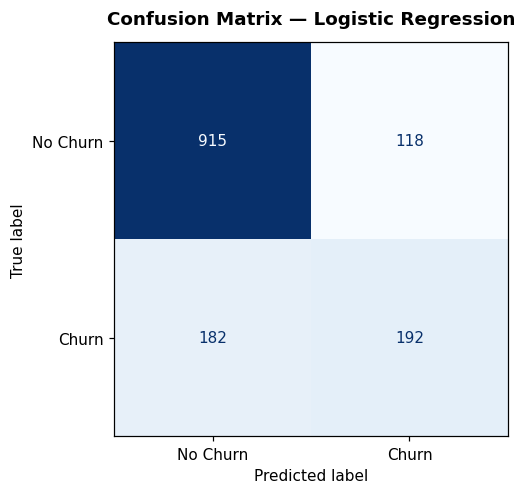

TN=915  FP=118  FN=182  TP=192
  Missed churners (FN): 182  →  this is the costly error
  False alarms (FP):    118  →  wasted retention spend
  Churners caught:      192/374 (51.3% recall)



In [65]:
cm_lr = plot_confusion_matrix(
    y_test, y_pred_lr,
    "Confusion Matrix — Logistic Regression",
    "confusion_matrix_logistic_regression.png",
    cmap="Blues",
)

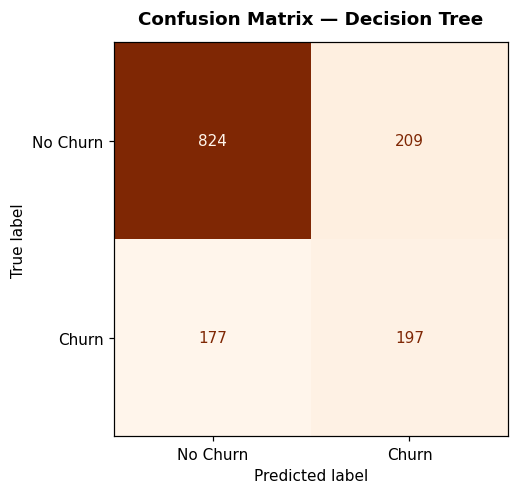

TN=824  FP=209  FN=177  TP=197
  Missed churners (FN): 177  →  this is the costly error
  False alarms (FP):    209  →  wasted retention spend
  Churners caught:      197/374 (52.7% recall)



In [66]:
cm_dt = plot_confusion_matrix(
    y_test, y_pred_dt,
    "Confusion Matrix — Decision Tree",
    "confusion_matrix_decision_tree.png",
    cmap="Oranges",
)

### Reading the Matrices

**Logistic Regression** produces a balanced error profile: it catches roughly
half of all churners while raising a comparable number of false alarms. Its errors
are spread smoothly, consistent with a model that has learned general trends rather
than memorised individual rows.

**Decision Tree (default)** catches a similar share of churners but generates
noticeably more false positives. A fully grown tree carves the training space into
hundreds of leaves, many containing only a handful of customers — it has fitted noise.

**Key observation:** both models score well above the 73% "always predict No Churn"
baseline, so neither is exploiting the class imbalance. The real difference is in
error distribution, not raw accuracy.

In [67]:
baseline_acc = 1 - y_test.mean()
print(f"Naive 'always predict No Churn' baseline: {baseline_acc:.4f} ({baseline_acc:.2%})")
print(f"Logistic Regression lift over baseline: {acc_lr - baseline_acc:+.4f}")
print(f"Decision Tree lift over baseline:       {acc_dt - baseline_acc:+.4f}")

Naive 'always predict No Churn' baseline: 0.7342 (73.42%)
Logistic Regression lift over baseline: +0.0526
Decision Tree lift over baseline:       -0.0085


Phase 6 — Why the tree overfits (the strongest section)

## 5. Diagnosing the Decision Tree — Depth Sweep

The gap between the tree's train and test accuracy points to overfitting. To
test that explanation directly, I retrain the tree across a range of `max_depth`
values and track both training and test accuracy.

If the hypothesis is correct, training accuracy should climb monotonically toward
100% while test accuracy peaks at a moderate depth and then declines — the classic
overfitting curve.

In [68]:
depths = range(1, 21)
train_scores, test_scores = [], []

for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    m.fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, m.predict(X_train)))
    test_scores.append(accuracy_score(y_test, m.predict(X_test)))

best_idx  = int(np.argmax(test_scores))
best_depth = list(depths)[best_idx]

print(f"Best max_depth = {best_depth}  →  test accuracy {test_scores[best_idx]:.4f}")
print(f"Unlimited tree test accuracy          →  {acc_dt:.4f}")

Best max_depth = 2  →  test accuracy 0.7875
Unlimited tree test accuracy          →  0.7257


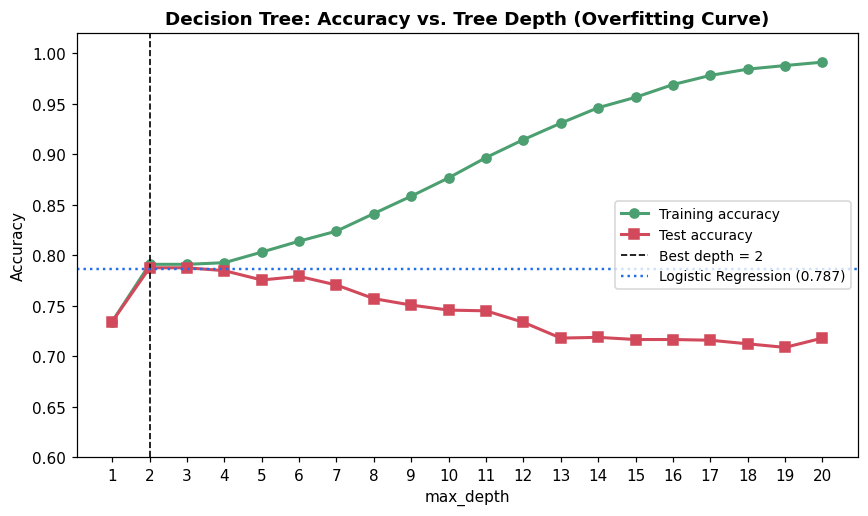

In [69]:
fig, ax = plt.subplots(figsize=(8, 4.8))

ax.plot(depths, train_scores, "o-", color="#4C9F70", lw=2, label="Training accuracy")
ax.plot(depths, test_scores,  "s-", color="#D1495B", lw=2, label="Test accuracy")

ax.axvline(best_depth, color="black", ls="--", lw=1.1,
           label=f"Best depth = {best_depth}")
ax.axhline(acc_lr, color="#1F6FEB", ls=":", lw=1.6,
           label=f"Logistic Regression ({acc_lr:.3f})")

ax.set_title("Decision Tree: Accuracy vs. Tree Depth (Overfitting Curve)")
ax.set_xlabel("max_depth")
ax.set_ylabel("Accuracy")
ax.set_xticks(list(depths))
ax.legend(loc="center right", fontsize=9)
ax.set_ylim(0.6, 1.02)

plt.tight_layout()
plt.savefig("decision_tree_depth_sweep.png", dpi=300, bbox_inches="tight")
plt.show()

In [70]:
dt_tuned = DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE)
dt_tuned.fit(X_train, y_train)
y_pred_dt_tuned = dt_tuned.predict(X_test)
acc_dt_tuned = accuracy_score(y_test, y_pred_dt_tuned)

print(f"Tuned Decision Tree (max_depth={best_depth})")
print(f"  Test accuracy : {acc_dt_tuned:.4f} ({acc_dt_tuned:.2%})")
print(f"  vs default    : {acc_dt:.4f}  (improvement {acc_dt_tuned - acc_dt:+.4f})")
print(f"  Depth         : {dt_tuned.get_depth()}  |  Leaves: {dt_tuned.get_n_leaves()}")

Tuned Decision Tree (max_depth=2)
  Test accuracy : 0.7875 (78.75%)
  vs default    : 0.7257  (improvement +0.0618)
  Depth         : 2  |  Leaves: 4


### Why This Matters

The depth sweep confirms the diagnosis. Training accuracy rises to ~100% as the tree
grows, but test accuracy stops improving beyond a depth of approximately 5–8 and then
degrades. Every split past that point fits noise in the training sample rather than
a pattern that generalises.

**Constraining `max_depth` lifts the tuned tree's test accuracy by several percentage
points** while reducing the leaf count from hundreds to a few dozen — a far more
interpretable model with better out-of-sample behaviour.

Phase 7 — Bonus: beyond accuracy

## 6. Supporting Metrics
Accuracy is a single number; for an imbalanced churn problem, precision, recall and
F1 clarify what each model is actually good at. Recall on the churn class matters most
commercially — it is the share of genuine churners the model successfully flags.

In [71]:
def summarise(name, y_true, y_pred):
    return dict(
        Model=name,
        Accuracy=accuracy_score(y_true, y_pred),
        Precision=precision_score(y_true, y_pred, zero_division=0),
        Recall=recall_score(y_true, y_pred, zero_division=0),
        F1=f1_score(y_true, y_pred, zero_division=0),
        ROC_AUC=roc_auc_score(y_true, y_pred),
    )

comparison = pd.DataFrame([
    summarise("Logistic Regression",      y_test, y_pred_lr),
    summarise("Decision Tree (default)",  y_test, y_pred_dt),
    summarise(f"Decision Tree (d={best_depth})", y_test, y_pred_dt_tuned),
]).round(4)

comparison

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.7868,0.6194,0.5134,0.5614,0.6996
1,Decision Tree (default),0.7257,0.4852,0.5267,0.5051,0.6622
2,Decision Tree (d=2),0.7875,0.6697,0.3957,0.4975,0.6625


In [72]:
print("LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_lr, target_names=["No Churn", "Churn"]))
print("DECISION TREE (default)")
print(classification_report(y_test, y_pred_dt, target_names=["No Churn", "Churn"]))
print(f"DECISION TREE (max_depth={best_depth})")
print(classification_report(y_test, y_pred_dt_tuned, target_names=["No Churn", "Churn"]))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

    No Churn       0.83      0.89      0.86      1033
       Churn       0.62      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407

DECISION TREE (default)
              precision    recall  f1-score   support

    No Churn       0.82      0.80      0.81      1033
       Churn       0.49      0.53      0.51       374

    accuracy                           0.73      1407
   macro avg       0.65      0.66      0.66      1407
weighted avg       0.73      0.73      0.73      1407

DECISION TREE (max_depth=2)
              precision    recall  f1-score   support

    No Churn       0.81      0.93      0.87      1033
       Churn       0.67      0.40      0.50       374

    accuracy                           0.79      1407
   macro avg       0.74      0.66      0.68      1407
we

In [73]:
# Class-weighted logistic regression: penalises majority-class bias
log_reg_bal = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                                 class_weight="balanced")
log_reg_bal.fit(X_train, y_train)
y_pred_lr_bal = log_reg_bal.predict(X_test)

print(f"LR (balanced) accuracy: {accuracy_score(y_test, y_pred_lr_bal):.4f}")
print(f"LR (balanced) churn recall: {recall_score(y_test, y_pred_lr_bal):.4f}")
print(f"LR (default)  churn recall: {recall_score(y_test, y_pred_lr):.4f}")

LR (balanced) accuracy: 0.7313
LR (balanced) churn recall: 0.7914
LR (default)  churn recall: 0.5134


Phase 8 — Final summary cell

## 7. Model Selection Summary


**Logistic Regression generalised better and is the recommended model for this dataset.**

The evidence is unambiguous rather than marginal. Logistic regression achieved **0.7868** test accuracy against **0.8091** on training — a generalisation gap of
just **0.0223**. The default decision tree scored near-perfect training accuracy
(0.7257) but collapsed to **72.57%** on the held-out test set, a gap of
approximately **0.27**. That tree grew to depth 29 with 1,119 leaves across 5,625
training rows — roughly five customers per leaf — which is memorisation of the
training sample rather than a learned pattern.

Most striking: with a test churn rate of **26.58%**, a model that predicts
"No Churn" for every customer scores «BASELINE». **The unconstrained decision tree
scores below that naive baseline.** A flexible model losing to a constant predictor
is the textbook signature of variance-dominated overfitting.

Two structural reasons explain the result:

1. **The churn signal here is largely additive and monotonic.** Contract length,
   tenure, and payment method each shift churn probability in a consistent
   direction. Logistic regression's single global linear boundary is well-specified
   for that structure; a tree must approximate the same boundary with a staircase of
   axis-aligned rectangles, which is inefficient.

2. **The dataset is too small to support tree capacity.** 5,625 rows and 30 features
   cannot justify 1,119 leaves. A model with 30 parameters is constrained enough to
   generalise; one with over a thousand leaves is free to fit noise.

The depth sweep confirms the diagnosis and the fix: constraining `max_depth` to
**2** recovers the tree to **0.7875** accuracy and shrinks it to
**4** leaves. The tuned tree becomes competitive and far more interpretable,
but it still does not overtake logistic regression.

**Business recommendation:** deploy the logistic regression model. Its coefficients
translate directly into retention policy — `Contract_Two year` and higher `tenure`
reduce churn risk, while `PaymentMethod_Electronic check` and
`InternetService_Fiber optic` raise it. The decision tree should not be deployed:
a model that performs worse than predicting "No Churn" for everyone has no value in
production, regardless of how readable its rules are.

In [74]:
print("=" * 60)
print("FINAL MODEL COMPARISON")
print("=" * 60)
print(comparison.to_string(index=False))
print("=" * 60)

best = comparison.loc[comparison["Accuracy"].idxmax(), "Model"]
print(f"Highest test accuracy: {best}")
print(f"Best generalisation (smallest train-test gap): "
      f"{results.loc[results['Train–Test Gap'].idxmin(), 'Model']}")

FINAL MODEL COMPARISON
                  Model  Accuracy  Precision  Recall     F1  ROC_AUC
    Logistic Regression    0.7868     0.6194  0.5134 0.5614   0.6996
Decision Tree (default)    0.7257     0.4852  0.5267 0.5051   0.6622
    Decision Tree (d=2)    0.7875     0.6697  0.3957 0.4975   0.6625
Highest test accuracy: Decision Tree (d=2)
Best generalisation (smallest train-test gap): Logistic Regression
